In [7]:
## a useful function to generate a data list for further analysis
import os
data_list=[]
input_path = 'Z:/DATA/experiment_trackball_Optomotor'
dataset=os.listdir(input_path)
#exp_date=['220813','220811','220814']
#exp_date=['221015','221016']
exp_date=['221102','221103']
exp_name='sweeploom'
for locust in dataset:
    locust_directory=input_path + '/' + locust
    file_list = os.listdir(locust_directory)
    for thisDate in file_list:
        if thisDate in exp_date:
            experiment_directory=locust_directory + '/' + thisDate
            experiment_list=os.listdir(experiment_directory)
            for thisExperiment in experiment_list:
                if thisExperiment in exp_name:
                    data_list.append(experiment_directory + '/' + exp_name)

In [ ]:
##The meta information of the stimulus is now included in each cell when the stimulus is delivered
##They are saved as stim_variable object.
##For gratings: it only includs temporal frequency at the moment 2022 sep 6th
##For sweeploom: it includs the initial and ending size; initial and ending position, by this order 
##For sweeploom: it includs stimid, size, Colour1, numDots1, Contrast1, VelX1, Coherence1 by this order 
import os, fnmatch
import pandas as pd
import numpy as np
import re
def generate_curated_database(myList = [], *args):
    overwrite_file=True
    save_file=True
    #csv_pattern='trial_*.csv'
    dat_pattern='*.dat'    
    track_ball_radius=40
    frame_rate=144
    #stim_duration = 25 # in sec
    #grey_duration = 5
    for thisDir in myList:
        # list up the files in the dir
        file = os.listdir(thisDir)
        # look for files that matches the pattern
        dat_file= fnmatch.filter(file, dat_pattern)
        dat_file_directory= os.path.join(thisDir ,dat_file[0])

   
        ## load dat file
    
        raw_data = pd.read_table(dat_file_directory, sep="\s+")
        ## fictrac title is here 'frame counter', 'delta rotation vector cam x', 'delta rotation vector cam y', \
        ##'delta rotation vector cam z', 'delta rotation error score', 'delta rotation vector lab x', \
        ##'delta rotation vector lab y', 'delta rotation vector lab z', 'absolute rotation vector cam x',\
        ##'absolute rotation vector cam y', 'absolute rotation vector cam z', \
        ##'absolute rotation vector lab x', 'absolute rotation vector lab y', \
        ##'absolute rotation vector lab z', 'intergrated x position','intergrated y position', \
        ##'intergrated animal heading', 'animal movement direction', 'animal movement speed', \
        ##'intergrated forward motion','intergrated side motion', 'timestamp', 'sequence counter','delta timestamp', 'alt. timestamp']

        ## drop some column
        raw_data.drop(raw_data.columns[[0,1,2,3,4,8,9,10,16,17,19,20,21,22,23]], axis=1, inplace=True)
        raw_data.columns=['delta rotation vector lab x', 'delta rotation vector lab y', 'delta rotation vector lab z',                       'absolute rotation vector lab x', 'absolute rotation vector lab y', 'absolute rotation vector lab z',                       'intergrated x position','intergrated y position','instant speed','timestamp']
        ## cleaning , and change the data from object to float
        raw_data.iloc[:, :]=raw_data.iloc[:, :].replace({',': ''}, regex= True)
        for ind in range(0, raw_data.shape[1]):
            raw_data.iloc[:, ind]=pd.to_numeric(raw_data.iloc[:, ind]).astype('float32')
        
        ## adjust the unit of the x, y position
        raw_data.iloc[:, 6]=raw_data.iloc[:, 6]*track_ball_radius
        raw_data.iloc[:, 7]=raw_data.iloc[:, 7]*track_ball_radius
        raw_data.iloc[:, 8]=raw_data.iloc[:, 8]*track_ball_radius*frame_rate
        ## adjust the unit of the z vector based on the target frame rate of fictrac
        raw_data.iloc[:, 2]=raw_data.iloc[:, 2]
  
        ### save the curated_database
        if save_file==True:
            database_name='database_curated.pickle'
            database_directory= os.path.join(thisDir,database_name)
            if (overwrite_file ==False) and (os.path.isfile == True):
                continue
            else:
                raw_data.to_pickle(database_directory)

In [ ]:
generate_curated_database(data_list)

#### main analysis starts

In [10]:
## this is a custom function to calculate deceleration based on 2 std
def a_guest(x):
    b = np.zeros_like(x, dtype=bool)
    i = np.argmax(x, axis=1)
    b[np.arange(i.size), i] = np.logical_or.reduce(x, axis=1)
    return b
def deceleration_detection(v_array = [], *args):
    V0=v_array[:,init_time*frame_rate:int((init_time+0.5)*frame_rate),0]
    meanV0=np.mean(V0, axis=1)
    stdV0=np.std(V0, axis=1, ddof=1)
    deceleration_threshold=meanV0-2*stdV0
    velocity_of_interest=v_array[:,int((init_time+0.5)*frame_rate):int((init_time+presence_duration+0.5)*frame_rate),0]
    dece_big=np.reshape(np.repeat(deceleration_threshold,presence_duration*frame_rate,axis=0),(len(deceleration_threshold),presence_duration*frame_rate))
    dec=np.less(dece_big,velocity_of_interest)
    rev=np.fliplr(dec)
    dev_onset=np.where(a_guest(rev)==True)
    velocity_of_interest.shape[1]-dev_onset[1]
    return dev_onset

In [13]:
thisDir=data_list[7]

In [4]:
import pandas as pd
df=pd.read_pickle(r"Z:\DATA\experiment_trackball_Optomotor\L22141\221103\sweeploom\database_curated.pickle")

In [10]:
df

,delta rotation vector lab x,delta rotation vector lab y,delta rotation vector lab z,absolute rotation vector lab x,absolute rotation vector lab y,absolute rotation vector lab z,intergrated x position,intergrated y position,instant speed,timestamp
0,0.001255,-0.007392,-0.010899,1.797118,1.781270,-0.634037,-0.295407,-0.051800,43.187843,53223436.0
1,0.001814,0.000742,-0.000219,1.798526,1.782708,-0.633449,-0.264928,-0.124013,11.286987,53223440.0
2,0.015608,-0.001173,0.001662,1.807175,1.792914,-0.619337,-0.305422,-0.748778,90.154938,53223448.0
3,0.004657,0.005111,0.041771,1.768037,1.832098,-0.604581,-0.103143,-0.937383,39.828209,53223456.0
4,0.019435,0.015957,0.036190,1.743415,1.882629,-0.590375,0.495113,-1.745920,144.843170,53223460.0
...,...,...,...,...,...,...,...,...,...,...
355138,0.011998,0.007245,-0.012065,0.450877,1.152935,0.753824,-1806.272095,247.336700,80.730240,55689616.0
355139,0.010260,0.009702,0.005397,0.460603,1.160196,0.763265,-1805.758667,247.101562,81.338646,55689624.0
355140,0.009267,-0.005547,-0.018734,0.476208,1.146145,0.753547,-1805.822632,246.674332,62.208160,55689632.0
355141,0.005061,-0.000286,-0.005459,0.483280,1.142498,0.751915,-1805.753784,246.483612,29.196627,55689636.0


C:\Users\neuroPC\AppData\Local\Temp\ipykernel_18792\2606849042.py:564: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  fig = plt.figure()


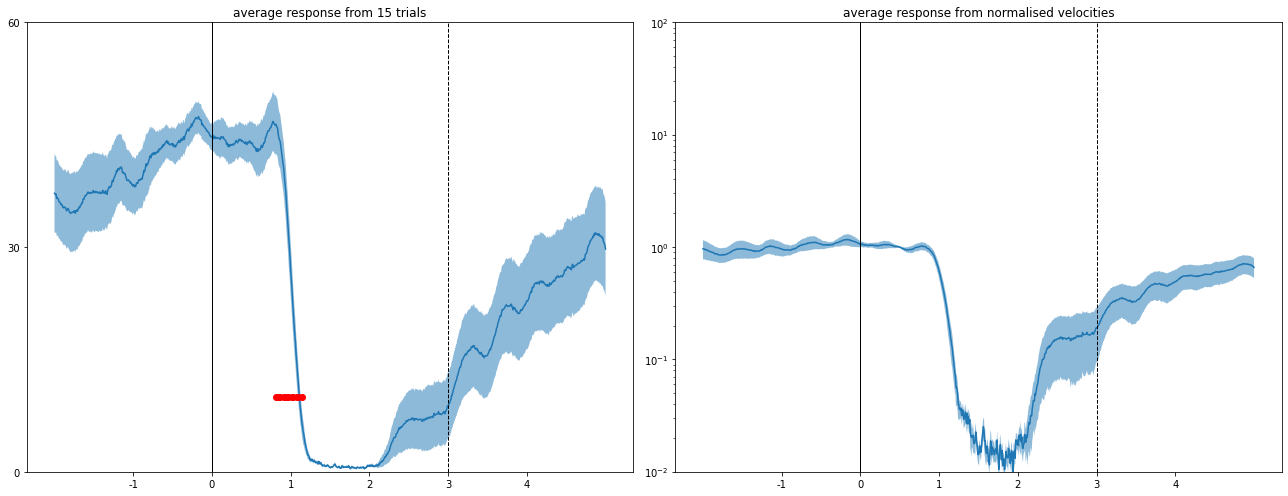

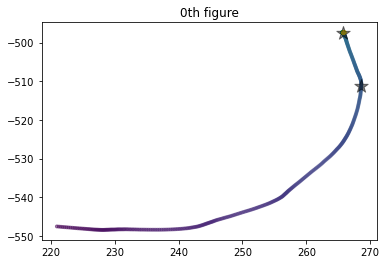

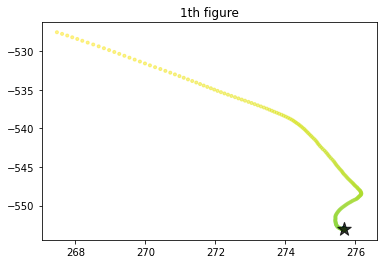

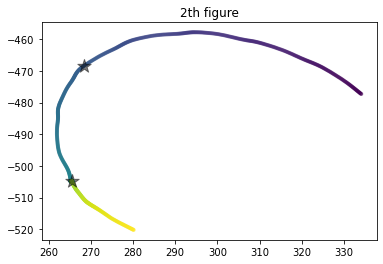

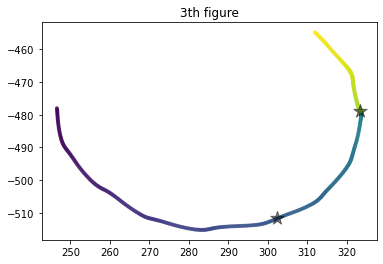

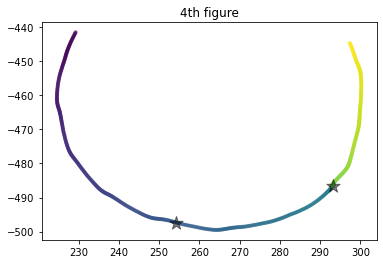

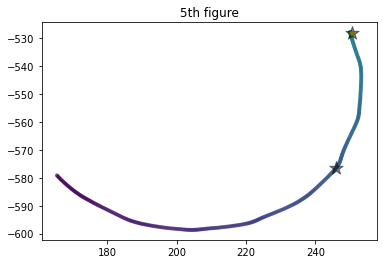

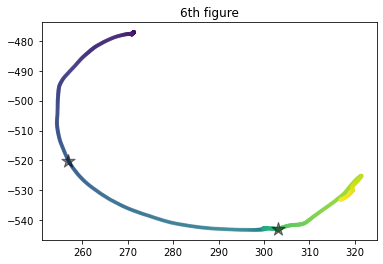

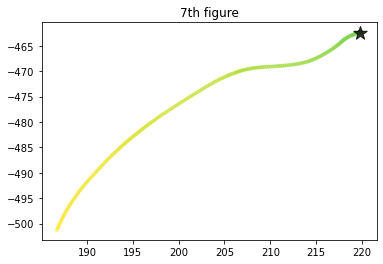

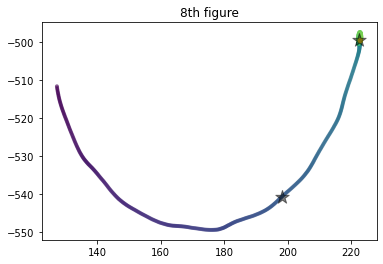

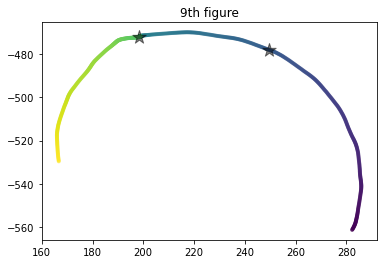

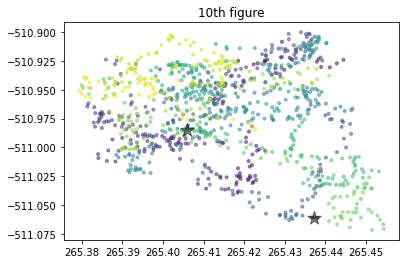

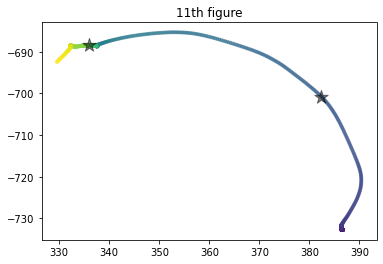

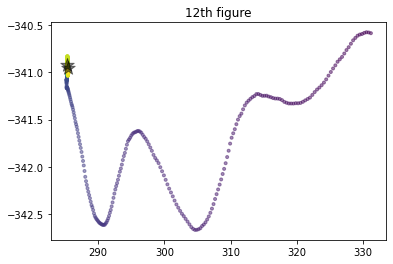

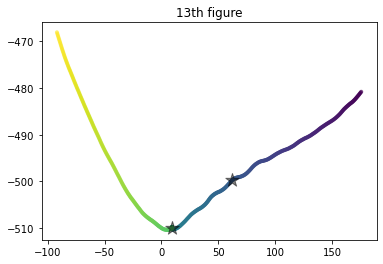

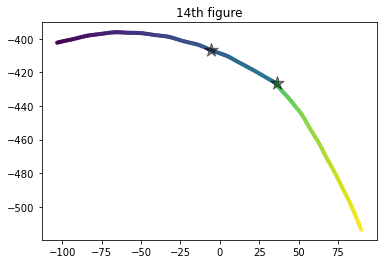

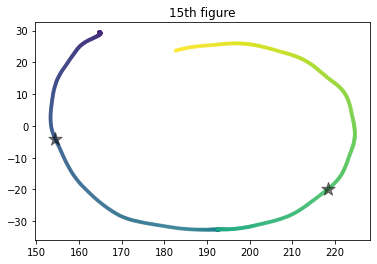

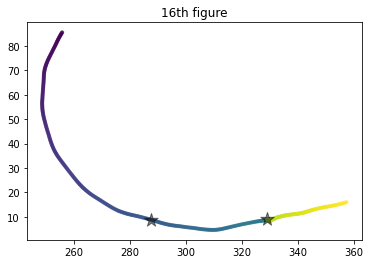

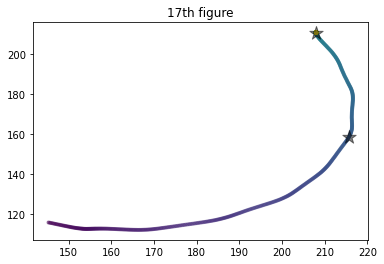

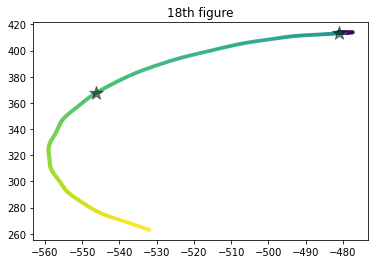

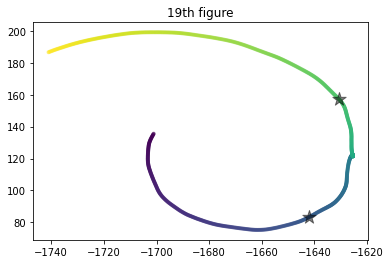

In [38]:
##this is the batch analysis for dual looming assay across different stimulus types
##output ploting decerleration
## any question: check on chiyu's push commit 9f74181 on the github, which was deleted for some technical reasons
import os, fnmatch
import pandas as pd
import numpy as np
import re
from scipy.signal import savgol_filter
import matplotlib.pyplot as plt
#def generate_preliminary_graph(myList = [], *args):
csv_pattern='trial_*.csv'
database_pattern='*.pickle'
exp_name='sweeploom'
frame_rate=144
analysis_window=[-2, 5]
window_length=analysis_window[1]-analysis_window[0]
stim_type=["c2b_f_sloom","c2b_s_sloom","c2f_f_sloom","c2f_s_sloom","c2c_f_loom","c2c_s_loom"]
save_fig = False
closed_loop_experiment = False
sg_filering= True
plot_response_overview = False
analyse_every_stimulus = False
analyse_trial_by_time = False
plotting_ThisExperiment_trajectory = False
plotting_SingleTrial_trajectory = True
plotting_SingleTrial_velocity=False
##this is an option to plot individual trajectory of each trial
##loop through the entire list of animals
#fig, (ax1,ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18,7),tight_layout=True)


mean_travel_distance_during_stim=[]
mean_normalised_distance_during_stim=[]
trial_num=[]
travel_distance_prior_stim_all=[]
travel_distance_tbt=[]
velocity_list=[]
distance_change_t1=[]
distance_change_t2=[]
stimulus_order=[]
deceleration_across_stim=[]
files = os.listdir(thisDir)
db_file= fnmatch.filter(files, database_pattern)
df=pd.read_pickle(os.path.join(thisDir,db_file[0]))
if sg_filering == True:
    x_all = savgol_filter(df.loc[:, ['intergrated x position']], 71, 3, axis=0)
    y_all = savgol_filter(df.loc[:, ['intergrated y position']], 71, 3, axis=0)
    instant_v=savgol_filter(df.loc[:, ['instant speed']], 39, 3, axis=0)
    runmean_v=df['instant speed'].rolling(10).mean().values
    #vx=savgol_filter(df.loc[:, ['instant speed']], 39, 3, axis=0)
    #vz=savgol_filter(df.loc[:, ['instant speed']], 39, 3, axis=0)
else:
    x_all = df.loc[:, ['intergrated x position']]
    y_all = df.loc[:, ['intergrated y position']]
    instant_v=df.loc[:, ['instant speed']]

if plotting_ThisExperiment_trajectory == True:
    plt.plot(x_all, y_all,c=np.arange(len(y_all)), marker='.', alpha=0.5)
    plt.show()   

csv_file= fnmatch.filter(files, csv_pattern)
stim_info = pd.read_csv(os.path.join(thisDir ,csv_file[0]))
stim_info=stim_info.reset_index()
stim_variable=[]
stimulus_timestamp=[]

if exp_name == 'gratings':
    for row in range(0, len(stim_info)):
    #delete the bracket in current speed and save it as integer in new list
        stim_variable.append(int(stim_info.loc[row, 'Frame'].replace('(', '')))
    # combine the last two values into the timestamp (were divided into 2 columns cause german computer
    # used comma as decimal seperator and save timestamp as float in new file
        if isinstance(stim_info.loc[row, 'Value'], float):
            timestamp = stim_info.loc[row, 'Timestamp']
        else:
            timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
        stimulus_timestamp.append(float(timestamp.replace(')', '')))
    stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))

elif exp_name == 'sweeploom':
    for row in range(0, len(stim_info)):
        stim_variable.append(int(stim_info.iloc[row,2].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,3].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,4].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,5].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,6].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,7].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,8].split("=",1)[1]))
        #stim_variable.append(int(re.split(r'=|}',stim_info.iloc[row,5])[1]))
        if isinstance(stim_info.loc[row, 'Value'], float):
            timestamp = stim_info.loc[row, 'Timestamp']
        else:
            timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
        stimulus_timestamp.append(float(timestamp.replace(')', '')))
    stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
    #some bugs in the bonsai workflow. Needs to remove the first timestamp and the last row of stim variable here
    if closed_loop_experiment == True:
        stimulus_timestamp.pop(0)
        stim_variable=np.delete(stim_variable, -1, axis=0)
elif exp_name == 'dots':
    for row in range(0, len(stim_info)):
        stim_variable.append(int(stim_info.iloc[row,2].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,4].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,5].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,7].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,11].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,13].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,17].split("=",1)[1]))
        if isinstance(stim_info.loc[row, 'Value'], float):
            timestamp = stim_info.loc[row, 'Timestamp']
        else:
            timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
        stimulus_timestamp.append(float(timestamp.replace(')', '')))
    stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
else:
    warnings.warn('stimulus paradigm can not be recognised')

stim_df=pd.DataFrame(stim_variable)    

    # compare the timestamp between event file and dat file
data_timestamp=df.loc[:, 'timestamp']
stimulus_timestamp_b=np.tile(stimulus_timestamp,(len(data_timestamp),1))
data_timestamp_b=np.tile(data_timestamp,(len(stimulus_timestamp),1))
timestamp_diff= data_timestamp_b > np.transpose(stimulus_timestamp_b)
stim_onset= np.where(np.roll(timestamp_diff,1,axis=1)!=timestamp_diff)[1][1::2]
stim_df["stim_onset"]=stim_onset

filters=[(stim_df.iloc[:,6]==1) & (stim_df.iloc[:,2] > stim_df.iloc[:,3]),
(stim_df.iloc[:,6]==2) & (stim_df.iloc[:,2] > stim_df.iloc[:,3]),
(stim_df.iloc[:,6]==1) & (stim_df.iloc[:,2] < stim_df.iloc[:,3]),
(stim_df.iloc[:,6]==2) & (stim_df.iloc[:,2] < stim_df.iloc[:,3]),
(stim_df.iloc[:,6]==1) & (stim_df.iloc[:,2] == stim_df.iloc[:,3]),
(stim_df.iloc[:,6]==2) & (stim_df.iloc[:,2] == stim_df.iloc[:,3])]

stim_df["stim_type"]=np.select(filters, stim_type)
if plot_response_overview == True:
    if analyse_trial_by_time == True:
        stim_to_analyse=stim_df.loc[:,'stim_onset']
        stim_name_list=np.array(stim_df["stim_type"])
        if re.search('_f_', thisStim):##create this condition so that stim_duration became dynamics
            stim_duration=3
            presence_duration=1
            sweep_duration=1
        elif re.search('_s_', thisStim):
            stim_duration=4
            presence_duration=1
            sweep_duration=2
        else:
            print('something wrong with the stim list')
            
        grey_onset=stim_to_analyse+np.ones(len(stim_to_analyse),dtype=int)*analysis_window[0]*frame_rate
        analysie_window_tile=np.tile(np.arange(window_length*frame_rate),(len(grey_onset),1))
        index_points=np.array(grey_onset).reshape(len(grey_onset),1)+analysie_window_tile
        x=x_all[index_points]
        y=y_all[index_points]
        x_dif=np.diff(x,axis=1)
        y_dif=np.diff(y,axis=1)
        travel_distance_fbf=np.sqrt(np.add(np.square(x_dif), np.square(y_dif)))
        velocity=travel_distance_fbf*frame_rate
        trial_num.append(velocity.shape[0])
        velocity_list.append(velocity[:,:,0])
        cum_travel_distance=np.cumsum(np.sqrt(np.add(np.square(x_dif), np.square(y_dif))),axis=1)
        init_time=abs(analysis_window[0])
        end_time=abs(analysis_window[0])+stim_duration
        travel_distance_prior_stim=cum_travel_distance[:,init_time*frame_rate,0]
        travel_distance_prior_stim_all.append(travel_distance_prior_stim)
        ##concatenate travel distance for histogram
        travel_distance_tbt_prior_stim=np.concatenate(travel_distance_prior_stim_all)
        ##concatenate velocity list for heatmap
        velocity_tbt=np.vstack(velocity_list)
        ##arrange xticks at onset and offset of the stimulus for heatmap
        heatmap_xticks=[abs(analysis_window[0])*frame_rate, (stim_duration+abs(analysis_window[0]))*frame_rate]
        trial_num_across_stim=np.cumsum(trial_num)

        fig, (ax1,ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18,7),tight_layout=True)
        ax1.hist(travel_distance_tbt_prior_stim, bins=20)
        ax1.set_xlabel('Speed (mm/s)')
        ax1.set_ylabel('Times')
        ax1.set_title('speed distribution before stim onset')
        ## draw subplot2
        #pcm=ax2.pcolormesh(velocity_tbt, cmap = 'magma',vmin = 0, vmax =100)
        pcm=ax2.pcolormesh(velocity_tbt, cmap = 'magma') ##sometimes, we dont need a vmax
        ## add colorbar
        fig.colorbar(pcm)
        ## add horizontal lines to indicate each stimulus type
        for ind in range(0,trial_num_across_stim.shape[0]):
            ax2.axhline(y=trial_num_across_stim[ind], color='white', linestyle='-', label='Stimulus Type',linewidth=0.5)
        ## remove y ticks for clearity and add y label
        ax2.set_yticks([])
        ax2.set_ylabel('Trial#')
        ## add vertical lines to indicate stimulus onset and offset
        ax2.axvline(x=heatmap_xticks[0], color='white', linestyle='-', label='Stimulus Starts')
        ax2.axvline(x=heatmap_xticks[1], color='white', linestyle='--', label='Fast Stimulus Ends')
        ax2.axvline(x=heatmap_xticks[1]+1*frame_rate, color='white', linestyle='--', label='Slow Stimulus Ends')
        ax2.set_xticks([heatmap_xticks[0],heatmap_xticks[1]])
        ax2.set_xticklabels(['0','3'])
        ax2.set_xlabel('Time (s)')
        ## add title
        ax2.set_title('stim_related response tbt')
        ## save the file

        plot_file_name=f'stim_heatmap_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
        if save_fig == True:
            plt.savefig(os.path.join(thisDir,plot_file_name))

    else:
        fig, (ax1,ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18,7),tight_layout=True)
        for thisStim in stim_type:
            stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== thisStim)),"stim_onset"]
            stim_name_list=stim_df.loc[stim_to_analyse.index,'stim_type'].values
            if re.search('_f_', thisStim):##create this condition so that stim_duration became dynamics
                stim_duration=3
                presence_duration=1
                sweep_duration=1
            elif re.search('_s_', thisStim):
                stim_duration=4
                presence_duration=1
                sweep_duration=2
            else:
                print('something wrong with the stim list')


            grey_onset=stim_to_analyse+np.ones(len(stim_to_analyse),dtype=int)*analysis_window[0]*frame_rate
            analysie_window_tile=np.tile(np.arange(window_length*frame_rate),(len(grey_onset),1))
            index_points=np.array(grey_onset).reshape(len(grey_onset),1)+analysie_window_tile
            x=x_all[index_points]
            y=y_all[index_points]
            x_dif=np.diff(x,axis=1)
            y_dif=np.diff(y,axis=1)
            travel_distance_fbf=np.sqrt(np.add(np.square(x_dif), np.square(y_dif)))
            velocity=travel_distance_fbf*frame_rate
            trial_num.append(velocity.shape[0])
            velocity_list.append(velocity[:,:,0])

            cum_travel_distance=np.cumsum(np.sqrt(np.add(np.square(x_dif), np.square(y_dif))),axis=1)
            init_time=abs(analysis_window[0])
            end_time=abs(analysis_window[0])+stim_duration
            travel_distance_prior_stim=cum_travel_distance[:,init_time*frame_rate,0]
            travel_distance_prior_stim_all.append(travel_distance_prior_stim)

        ##concatenate travel distance for histogram
        travel_distance_tbt_prior_stim=np.concatenate(travel_distance_prior_stim_all)
        ##concatenate velocity list for heatmap
        velocity_tbt=np.vstack(velocity_list)
        ##arrange xticks at onset and offset of the stimulus for heatmap
        heatmap_xticks=[abs(analysis_window[0])*frame_rate, (stim_duration+abs(analysis_window[0]))*frame_rate]
        trial_num_across_stim=np.cumsum(trial_num)


        ax1.hist(travel_distance_tbt_prior_stim, bins=20)
        ax1.set_xlabel('Speed (mm/s)')
        ax1.set_ylabel('Times')
        ax1.set_title('speed distribution before stim onset')
        ## draw subplot2
        #pcm=ax2.pcolormesh(velocity_tbt, cmap = 'magma',vmin = 0, vmax =100)
        pcm=ax2.pcolormesh(velocity_tbt, cmap = 'magma') ##sometimes, we dont need a vmax
        ## add colorbar
        fig.colorbar(pcm)
        ## add horizontal lines to indicate each stimulus type
        for ind in range(0,trial_num_across_stim.shape[0]):
            ax2.axhline(y=trial_num_across_stim[ind], color='white', linestyle='-', label='Stimulus Type',linewidth=0.5)
        ## remove y ticks for clearity and add y label
        ax2.set_yticks([])
        ax2.set_ylabel('Trial#')
        ## add vertical lines to indicate stimulus onset and offset
        ax2.axvline(x=heatmap_xticks[0], color='white', linestyle='-', label='Stimulus Starts')
        ax2.axvline(x=heatmap_xticks[1], color='white', linestyle='--', label='Fast Stimulus Ends')
        ax2.axvline(x=heatmap_xticks[1]+1*frame_rate, color='white', linestyle='--', label='Slow Stimulus Ends')
        ax2.set_xticks([heatmap_xticks[0],heatmap_xticks[1]])
        ax2.set_xticklabels(['0','3'])
        ax2.set_xlabel('Time (s)')
        ## add title
        ax2.set_title('stim_related response tbt')
        ## save the file

        plot_file_name=f'stim_heatmap_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
        if save_fig == True:
            plt.savefig(os.path.join(thisDir,plot_file_name))
        
else:
    if analyse_every_stimulus == True:
        for thisStim in stim_type:
            stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== thisStim)),"stim_onset"]
            stim_name_list=stim_df.loc[stim_to_analyse.index,'stim_type'].values
            if len(stim_to_analyse) ==0:
                print('no_required_stim_type')
                #continue

            if re.search('_f_', thisStim):##create this condition so that stim_duration became dynamics
                stim_duration=3
                presence_duration=1
                sweep_duration=1
            elif re.search('_s_', thisStim):
                stim_duration=4
                presence_duration=1
                sweep_duration=2
            else:
                print('something wrong with the stim list')

            grey_onset=stim_to_analyse+np.ones(len(stim_to_analyse),dtype=int)*analysis_window[0]*frame_rate
            analysie_window_tile=np.tile(np.arange(window_length*frame_rate),(len(grey_onset),1))
            index_points=np.array(grey_onset).reshape(len(grey_onset),1)+analysie_window_tile
            x=x_all[index_points]
            y=y_all[index_points]
            x_dif=np.diff(x,axis=1)
            y_dif=np.diff(y,axis=1)
            travel_distance_fbf=np.sqrt(np.add(np.square(x_dif), np.square(y_dif)))
            velocity=travel_distance_fbf*frame_rate
            cum_travel_distance=np.cumsum(np.sqrt(np.add(np.square(x_dif), np.square(y_dif))),axis=1)
            init_time=abs(analysis_window[0])
            end_time=abs(analysis_window[0])+stim_duration
            travel_distance_prior_stim=cum_travel_distance[:,init_time*frame_rate,0]
            travel_distance_post_stim=cum_travel_distance[:,end_time*frame_rate,0]

            travel_distance_after_stim_presence=cum_travel_distance[:,(init_time+presence_duration)*frame_rate,0]
            travel_distance_after_stim_sweep=cum_travel_distance[:,(init_time+presence_duration+sweep_duration)*frame_rate,0]
            travel_distance_during_stim_presence=travel_distance_after_stim_presence-travel_distance_prior_stim
            travel_distance_during_stim_sweep=travel_distance_after_stim_sweep-travel_distance_after_stim_presence
            normalised_distance_change=np.divide(travel_distance_during_stim_sweep,travel_distance_during_stim_presence)

            mean_travel_distance_post_stim=np.mean(travel_distance_post_stim)
            travel_distance_during_stim=travel_distance_post_stim-travel_distance_prior_stim
            normalise_travel_distance=np.divide(travel_distance_post_stim,travel_distance_prior_stim)  
            mean_normalise_travel_distance=np.mean(normalise_travel_distance)

            travel_distance_1sec_prior_stim=cum_travel_distance[:,init_time*frame_rate,0]-cum_travel_distance[:,(init_time-1)*frame_rate,0]
            running_trial=travel_distance_1sec_prior_stim>5
            running_velocity=velocity[running_trial,:]
            runnning_trial_distance_change=normalised_distance_change[running_trial]
            travel_distance_1sec_post_stim=cum_travel_distance[running_trial,(init_time+1)*frame_rate,0]-cum_travel_distance[running_trial,init_time*frame_rate,0]
            velocity_type1=running_velocity[travel_distance_1sec_post_stim>5,:]
            velocity_type2=running_velocity[travel_distance_1sec_post_stim<5,:]
            runnning_trial_distance_change_type1=runnning_trial_distance_change[travel_distance_1sec_post_stim>5]
            runnning_trial_distance_change_type2=runnning_trial_distance_change[travel_distance_1sec_post_stim<5]
            stimulus_order.append(sweep_duration)
            trial_to_analyse=velocity_type1

            travel_distance_prior_stim_all.append(travel_distance_prior_stim)
            travel_distance_tbt.append(cum_travel_distance)
            distance_change_t1.append(runnning_trial_distance_change_type1)
            distance_change_t2.append(runnning_trial_distance_change_type1)
            ## please tell me why I wanted to take mean here
            mean_travel_distance_during_stim.append(np.mean(travel_distance_during_stim))
            mean_normalised_distance_during_stim.append(np.mean(normalise_travel_distance))
            #travel_distance=np.sum(np.sqrt(np.add(np.square(x_dif), np.square(y_dif))),axis=1)
            vx=df.loc[:, ['delta rotation vector lab x']].values
            velocity_x=vx[index_points]
            vz=df.loc[:, ['delta rotation vector lab z']].values
            velocity_z=vz[index_points]
            velocity_rolling=runmean_v[index_points]
            tp=np.linspace(0,window_length,velocity.shape[1])
            tp_tile=np.tile(tp,(velocity.shape[0],1))

            #use deceleration_detection function which returns the index of onset but in a reverse order
            detected_epochs=deceleration_detection(trial_to_analyse)
            de_test=frame_rate*presence_duration-detected_epochs[1]
            dev_timing=de_test/frame_rate+0.5*presence_duration+init_time
            dev_timing_y=10*np.ones_like(dev_timing)
            mean_velocity=np.mean(trial_to_analyse[:,:,0], axis=0)
            sem_velocity=np.std(trial_to_analyse[:,:,0], axis=0, ddof=1) / np.sqrt(trial_to_analyse[:,:,0].shape[0])
            v_base=np.median(trial_to_analyse[:,init_time*frame_rate:(init_time+1)*frame_rate,0],axis=1)
            v_interest=trial_to_analyse[:,:,0]
            normalise_v=v_interest.T/v_base
            mean_velocity_norm=np.mean(normalise_v.T, axis=0)
            sem_velocity_norm=np.std(normalise_v.T, axis=0, ddof=1) / np.sqrt(normalise_v.T.shape[0])
            mean_tile=np.mean(tp_tile, axis=0)
            v_add_sem = mean_velocity + sem_velocity
            v_min_sem = mean_velocity - sem_velocity
            v_add_sem_norm = mean_velocity_norm + sem_velocity_norm
            v_min_sem_norm = mean_velocity_norm - sem_velocity_norm
            fig, (ax,ax2)= plt.subplots(nrows=1, ncols=2, figsize=(18,7),tight_layout=True)
            # ax=fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes
            ax.plot(mean_tile,mean_velocity)
            ax.plot(dev_timing, dev_timing_y, 'o', color='r')
            ax.fill_between(mean_tile,v_add_sem,v_min_sem, alpha=0.5, linewidth=0)
            ax.axvline(x=abs(analysis_window[0]), color='black', linestyle='-', label='Stim start',linewidth=1)
            ax.axvline(x=(abs(analysis_window[0])+stim_duration), color='black', linestyle='--', label='Stim end',linewidth=1)
            ax.set_ylim(0, 60)
            ax.set_yticks([0,30,60])
            ax.set_yticklabels(['0','30','60'])
            ax.set_xticks([1,2,3,4,5,6])
            ax.set_xticklabels(['-1','0','1','2','3','4'])
            plot_title=f'average response from {trial_to_analyse[:,:,0].shape[0]} trials'
            ax.set_title(plot_title)

            ax2.plot(mean_tile,mean_velocity_norm)
            ax2.fill_between(mean_tile,v_add_sem_norm,v_min_sem_norm, alpha=0.5, linewidth=0)
            ax2.axvline(x=abs(analysis_window[0]), color='black', linestyle='-', label='Stim start',linewidth=1)
            ax2.axvline(x=(abs(analysis_window[0])+stim_duration), color='black', linestyle='--', label='Stim end',linewidth=1)
            ax2.set_ylim(0.01, 100)
            ax2.set_yscale('log')
            ax2.set_xticks([1,2,3,4,5,6])
            ax2.set_xticklabels(['-1','0','1','2','3','4'])
            plot_title=f'average response from normalised velocities'
            ax2.set_title(plot_title)
            plot_file=f'stim_{stim_name_list[0]}_velocity_run_trials_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
            if save_fig == True:
                plt.savefig(thisDir+plot_file)
            if plotting_SingleTrial_velocity == True:
                v=1
                for thisVelocity in range(0, trial_to_analyse.shape[0]):

                    fig, (ax,ax2)= plt.subplots(nrows=1, ncols=2, figsize=(18,7),tight_layout=True)
                    ax.plot(mean_tile,trial_to_analyse[thisVelocity,:,0])
                    if thisVelocity in detected_epochs[0]:
                        thisTiming=dev_timing[detected_epochs[0]==thisVelocity]
                        thisValue=30*np.ones_like(thisTiming)

                        ax.plot(thisTiming, thisValue, 'o', color='r')
                    #ax.fill_between(mean_tile,v_add_sem,v_min_sem, alpha=0.5, linewidth=0)
                    ax.axvline(x=abs(analysis_window[0]), color='black', linestyle='-', label='Stim start',linewidth=1)
                    ax.axvline(x=(abs(analysis_window[0])+stim_duration), color='black', linestyle='--', label='Stim end',linewidth=1)
                    ax.set_ylim(0, 60)
                    ax.set_yticks([0,30,60])
                    ax.set_yticklabels(['0','30','60'])
                    ax.set_xticks([1,2,3,4,5,6])
                    ax.set_xticklabels(['-1','0','1','2','3','4'])
                    plot_title=f'single trial response{v}'
                    ax.set_title(plot_title)
                    plot_file=f'stim_{stim_name_list[0]}_velocity_run_trials_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
                    v=v+1
            if plotting_SingleTrial_trajectory == True:
                for ind in range(0,len(x)):
                    fig = plt.figure()
                    plt.scatter(x[ind,:],y[ind,:],c=np.arange(len(x[ind,:])), marker='.', alpha=0.5)
                    plt.scatter(x[ind,abs(analysis_window[0])*frame_rate],y[ind,abs(analysis_window[0])*frame_rate],s=200,c='k', marker='*', alpha=0.5)
                    plt.scatter(x[ind,(abs(analysis_window[0])+stim_duration)*frame_rate],y[ind,(abs(analysis_window[0])+stim_duration)*frame_rate],s=200,c='k', marker='*', alpha=0.5)
                    plot_file=f'stim_{stim_name_list[ind]}{str(ind)}_trajectory_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
                    plt.title(f'{ind}th figure')
    else:
    ## need to specify stimulus type here
        thisStim="c2f_f_sloom"
        stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== thisStim)),"stim_onset"]
        stim_name_list=stim_df.loc[stim_to_analyse.index,'stim_type'].values
        if len(stim_to_analyse) ==0:
            print('no_required_stim_type')
            #continue

        if re.search('_f_', thisStim):##create this condition so that stim_duration became dynamics
            stim_duration=3
            presence_duration=1
            sweep_duration=1
        elif re.search('_s_', thisStim):
            stim_duration=4
            presence_duration=1
            sweep_duration=2
        else:
            print('something wrong with the stim list')

        grey_onset=stim_to_analyse+np.ones(len(stim_to_analyse),dtype=int)*analysis_window[0]*frame_rate
        analysie_window_tile=np.tile(np.arange(window_length*frame_rate),(len(grey_onset),1))
        index_points=np.array(grey_onset).reshape(len(grey_onset),1)+analysie_window_tile
        x=x_all[index_points]
        y=y_all[index_points]
        x_dif=np.diff(x,axis=1)
        y_dif=np.diff(y,axis=1)
        travel_distance_fbf=np.sqrt(np.add(np.square(x_dif), np.square(y_dif)))
        velocity=travel_distance_fbf*frame_rate
        cum_travel_distance=np.cumsum(np.sqrt(np.add(np.square(x_dif), np.square(y_dif))),axis=1)
        init_time=abs(analysis_window[0])
        end_time=abs(analysis_window[0])+stim_duration
        travel_distance_prior_stim=cum_travel_distance[:,init_time*frame_rate,0]
        travel_distance_post_stim=cum_travel_distance[:,end_time*frame_rate,0]

        travel_distance_after_stim_presence=cum_travel_distance[:,(init_time+presence_duration)*frame_rate,0]
        travel_distance_after_stim_sweep=cum_travel_distance[:,(init_time+presence_duration+sweep_duration)*frame_rate,0]
        travel_distance_during_stim_presence=travel_distance_after_stim_presence-travel_distance_prior_stim
        travel_distance_during_stim_sweep=travel_distance_after_stim_sweep-travel_distance_after_stim_presence
        normalised_distance_change=np.divide(travel_distance_during_stim_sweep,travel_distance_during_stim_presence)

        mean_travel_distance_post_stim=np.mean(travel_distance_post_stim)
        travel_distance_during_stim=travel_distance_post_stim-travel_distance_prior_stim
        normalise_travel_distance=np.divide(travel_distance_post_stim,travel_distance_prior_stim)  
        mean_normalise_travel_distance=np.mean(normalise_travel_distance)

        travel_distance_1sec_prior_stim=cum_travel_distance[:,init_time*frame_rate,0]-cum_travel_distance[:,(init_time-1)*frame_rate,0]
        running_trial=travel_distance_1sec_prior_stim>5
        running_velocity=velocity[running_trial,:]
        runnning_trial_distance_change=normalised_distance_change[running_trial]
        travel_distance_1sec_post_stim=cum_travel_distance[running_trial,(init_time+1)*frame_rate,0]-cum_travel_distance[running_trial,init_time*frame_rate,0]
        velocity_type1=running_velocity[travel_distance_1sec_post_stim>5,:]
        velocity_type2=running_velocity[travel_distance_1sec_post_stim<5,:]
        runnning_trial_distance_change_type1=runnning_trial_distance_change[travel_distance_1sec_post_stim>5]
        runnning_trial_distance_change_type2=runnning_trial_distance_change[travel_distance_1sec_post_stim<5]
        stimulus_order.append(sweep_duration)
        trial_to_analyse=velocity_type1
        
        travel_distance_prior_stim_all.append(travel_distance_prior_stim)
        travel_distance_tbt.append(cum_travel_distance)
        distance_change_t1.append(runnning_trial_distance_change_type1)
        distance_change_t2.append(runnning_trial_distance_change_type1)
        ## please tell me why I wanted to take mean here
        mean_travel_distance_during_stim.append(np.mean(travel_distance_during_stim))
        mean_normalised_distance_during_stim.append(np.mean(normalise_travel_distance))
        #travel_distance=np.sum(np.sqrt(np.add(np.square(x_dif), np.square(y_dif))),axis=1)
        vx=df.loc[:, ['delta rotation vector lab x']].values
        velocity_x=vx[index_points]
        vz=df.loc[:, ['delta rotation vector lab z']].values
        velocity_z=vz[index_points]
        velocity_rolling=runmean_v[index_points]
        tp=np.linspace(0,window_length,velocity.shape[1])
        tp_tile=np.tile(tp,(velocity.shape[0],1))

        #use deceleration_detection function which returns the index of onset but in a reverse order
        detected_epochs=deceleration_detection(trial_to_analyse)
        de_test=frame_rate*presence_duration-detected_epochs[1]
        dev_timing=de_test/frame_rate+0.5*presence_duration+init_time
        dev_timing_y=10*np.ones_like(dev_timing)
        
        deceleration_frame_num_in_the_VOI=frame_rate-detected_epochs[1]
        deceleration_onset=0.5*presence_duration+deceleration_frame_num_in_the_VOI/frame_rate
        
        ##started to compile everything across stimulus type
        deceleration_across_stim.append(deceleration_onset)

        
        
        
        
        
        mean_velocity=np.mean(trial_to_analyse[:,:,0], axis=0)
        sem_velocity=np.std(trial_to_analyse[:,:,0], axis=0, ddof=1) / np.sqrt(trial_to_analyse[:,:,0].shape[0])
        v_base=np.median(trial_to_analyse[:,init_time*frame_rate:(init_time+1)*frame_rate,0],axis=1)
        v_interest=trial_to_analyse[:,:,0]
        normalise_v=v_interest.T/v_base
        mean_velocity_norm=np.mean(normalise_v.T, axis=0)
        sem_velocity_norm=np.std(normalise_v.T, axis=0, ddof=1) / np.sqrt(normalise_v.T.shape[0])
        mean_tile=np.mean(tp_tile, axis=0)
        v_add_sem = mean_velocity + sem_velocity
        v_min_sem = mean_velocity - sem_velocity
        v_add_sem_norm = mean_velocity_norm + sem_velocity_norm
        v_min_sem_norm = mean_velocity_norm - sem_velocity_norm
        fig, (ax,ax2)= plt.subplots(nrows=1, ncols=2, figsize=(18,7),tight_layout=True)
        # ax=fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes
        ax.plot(mean_tile,mean_velocity)
        ax.plot(dev_timing, dev_timing_y, 'o', color='r')
        ax.fill_between(mean_tile,v_add_sem,v_min_sem, alpha=0.5, linewidth=0)
        ax.axvline(x=abs(analysis_window[0]), color='black', linestyle='-', label='Stim start',linewidth=1)
        ax.axvline(x=(abs(analysis_window[0])+stim_duration), color='black', linestyle='--', label='Stim end',linewidth=1)
        ax.set_ylim(0, 60)
        ax.set_yticks([0,30,60])
        ax.set_yticklabels(['0','30','60'])
        ax.set_xticks([1,2,3,4,5,6])
        ax.set_xticklabels(['-1','0','1','2','3','4'])
        plot_title=f'average response from {trial_to_analyse[:,:,0].shape[0]} trials'
        ax.set_title(plot_title)

        ax2.plot(mean_tile,mean_velocity_norm)
        ax2.fill_between(mean_tile,v_add_sem_norm,v_min_sem_norm, alpha=0.5, linewidth=0)
        ax2.axvline(x=abs(analysis_window[0]), color='black', linestyle='-', label='Stim start',linewidth=1)
        ax2.axvline(x=(abs(analysis_window[0])+stim_duration), color='black', linestyle='--', label='Stim end',linewidth=1)
        ax2.set_ylim(0.01, 100)
        ax2.set_yscale('log')
        ax2.set_xticks([1,2,3,4,5,6])
        ax2.set_xticklabels(['-1','0','1','2','3','4'])
        plot_title=f'average response from normalised velocities'
        ax2.set_title(plot_title)
        plot_file=f'stim_{stim_name_list[0]}_velocity_run_trials_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
        if save_fig == True:
            plt.savefig(thisDir+plot_file)
        if plotting_SingleTrial_velocity == True:
            v=1
            for thisVelocity in range(0, trial_to_analyse.shape[0]):

                fig, (ax,ax2)= plt.subplots(nrows=1, ncols=2, figsize=(18,7),tight_layout=True)
                ax.plot(mean_tile,trial_to_analyse[thisVelocity,:,0])
                if thisVelocity in detected_epochs[0]:
                    thisTiming=dev_timing[detected_epochs[0]==thisVelocity]
                    thisValue=30*np.ones_like(thisTiming)

                    ax.plot(thisTiming, thisValue, 'o', color='r')
                #ax.fill_between(mean_tile,v_add_sem,v_min_sem, alpha=0.5, linewidth=0)
                ax.axvline(x=abs(analysis_window[0]), color='black', linestyle='-', label='Stim start',linewidth=1)
                ax.axvline(x=(abs(analysis_window[0])+stim_duration), color='black', linestyle='--', label='Stim end',linewidth=1)
                ax.set_ylim(0, 60)
                ax.set_yticks([0,30,60])
                ax.set_yticklabels(['0','30','60'])
                ax.set_xticks([1,2,3,4,5,6])
                ax.set_xticklabels(['-1','0','1','2','3','4'])
                plot_title=f'single trial response{v}'
                ax.set_title(plot_title)
                plot_file=f'stim_{stim_name_list[0]}_velocity_run_trials_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
                v=v+1
        if plotting_SingleTrial_trajectory == True:
            for ind in range(0,len(x)):
                fig = plt.figure()
                plt.scatter(x[ind,:],y[ind,:],c=np.arange(len(x[ind,:])), marker='.', alpha=0.5)
                plt.scatter(x[ind,abs(analysis_window[0])*frame_rate],y[ind,abs(analysis_window[0])*frame_rate],s=200,c='k', marker='*', alpha=0.5)
                plt.scatter(x[ind,(abs(analysis_window[0])+stim_duration)*frame_rate],y[ind,(abs(analysis_window[0])+stim_duration)*frame_rate],s=200,c='k', marker='*', alpha=0.5)
                plot_file=f'stim_{stim_name_list[ind]}{str(ind)}_trajectory_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
                plt.title(f'{ind}th figure')

In [ ]:
## just a cell to store different filters for other stimulus paradigm

filters=[(stim_df.iloc[:,6]==1) & (stim_df.iloc[:,2] > stim_df.iloc[:,3]),
(stim_df.iloc[:,6]==2) & (stim_df.iloc[:,2] > stim_df.iloc[:,3]),
(stim_df.iloc[:,6]==1) & (stim_df.iloc[:,2] < stim_df.iloc[:,3]),
(stim_df.iloc[:,6]==2) & (stim_df.iloc[:,2] < stim_df.iloc[:,3]),
(stim_df.iloc[:,6]==1) & (stim_df.iloc[:,2] == stim_df.iloc[:,3]),
(stim_df.iloc[:,6]==2) & (stim_df.iloc[:,2] == stim_df.iloc[:,3])]


### use this criteria for experiments during exp_date=['221015','221016']
#filters=[(stim_df.iloc[:,0]==1) & (stim_df.iloc[:,2] > stim_df.iloc[:,3]),
#(stim_df.iloc[:,0]==8) & (stim_df.iloc[:,2] > stim_df.iloc[:,3]),
#(stim_df.iloc[:,0]==1) & (stim_df.iloc[:,2] < stim_df.iloc[:,3]),
#(stim_df.iloc[:,0]==8) & (stim_df.iloc[:,2] < stim_df.iloc[:,3]),
#(stim_df.iloc[:,0]==1) & (stim_df.iloc[:,2] == stim_df.iloc[:,3]),
#(stim_df.iloc[:,0]==8) & (stim_df.iloc[:,2] == stim_df.iloc[:,3])]

In [ ]:
## a plotting function if there is a need to quantify deceleration onset across animals 
    dates=[1,2,3]
    values=[np.mean(deceleration_across_stim[1]),np.mean(deceleration_across_stim[5]),np.mean(deceleration_across_stim[3])]
    yerr=[np.std(deceleration_across_stim[1], axis=0, ddof=1)/np.sqrt(deceleration_across_stim[1].shape[0]),np.std(deceleration_across_stim[5], axis=0, ddof=1) / np.sqrt(deceleration_across_stim[5].shape[0]),np.std(deceleration_across_stim[3], axis=0, ddof=1) / np.sqrt(deceleration_across_stim[3].shape[0])]
    ax1.plot(dates, values, 'o-') 
    ax1.errorbar(dates, values,yerr=yerr,fmt='-o')
    values=[np.mean(deceleration_across_stim[0]),np.mean(deceleration_across_stim[4]),np.mean(deceleration_across_stim[2])]
    yerr=[np.std(deceleration_across_stim[0], axis=0, ddof=1)/np.sqrt(deceleration_across_stim[0].shape[0]),np.std(deceleration_across_stim[4], axis=0, ddof=1) / np.sqrt(deceleration_across_stim[4].shape[0]),np.std(deceleration_across_stim[2], axis=0, ddof=1) / np.sqrt(deceleration_across_stim[2].shape[0])]
    ax2.plot(dates, values, 'o-')
    ax2.errorbar(dates, values,yerr=yerr,fmt='-o')


    ax1.set_xlabel('stimulus type')
    ax1.set_ylabel('Deceleration onset (s)')
    ax2.set_xlabel('stimulus type')
    ax2.set_ylabel('Deceleration onset (s)')
    ax1.set_title('slow stimulus')
    ax2.set_title('fast stimulus')
    ax1.set_ylim(0,1.5)
    ax2.set_ylim(0,1.5)
    ax1.set_xticks([1,2,3])
    ax1.set_xticklabels(['back','center','front'])
    ax2.set_xticks([1,2,3])
    ax2.set_xticklabels(['back','center','front'])
    ax1.set_xlim(0,4)
    ax2.set_xlim(0,4)